
# Multiple Object Video Detection

**Computer Vision — UCU AI 2026**

## 1. Data Understanding and Preprocessing

In this section, we explore the VisDrone dataset, examine class distributions, object sizes, and scene density, and prepare the data for object detection models.

We use sequence-level train/validation separation to prevent data leakage between frames from the same video.


In [26]:

from pathlib import Path
import json
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


In [27]:

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "multiple-object-video-detection-hw-2-ucu-ai-2026"
)

TRAIN_PATH = DATASET_PATH / "train"
VAL_PATH = DATASET_PATH / "val"
TEST_PATH = DATASET_PATH / "test"

TRAIN_IMAGES = TRAIN_PATH / "images"
VAL_IMAGES = VAL_PATH / "images"
TEST_IMAGES = TEST_PATH / "images"

TRAIN_ANNOTATIONS = TRAIN_PATH / "annotations_coco.json"
VAL_ANNOTATIONS = VAL_PATH / "annotations_coco.json"

TEST_CSV = DATASET_PATH / "test_images.csv"


In [28]:

required_paths = {
    "Train images": TRAIN_IMAGES,
    "Validation images": VAL_IMAGES,
    "Test images": TEST_IMAGES,
    "Train annotations": TRAIN_ANNOTATIONS,
    "Validation annotations": VAL_ANNOTATIONS,
    "Test metadata": TEST_CSV,
}

for name, path in required_paths.items():
    assert path.exists(), f"Missing {name}: {path}"

print("Dataset paths verified successfully.")


Dataset paths verified successfully.



## 3. Dataset Understanding

### 3.1 Dataset Overview

We use the COCO annotation format, which stores image metadata, object annotations, and category definitions.

We first load the training and validation annotations to examine the dataset structure.


In [29]:

with open(TRAIN_ANNOTATIONS, "r", encoding="utf-8") as file:
    train_coco = json.load(file)

with open(VAL_ANNOTATIONS, "r", encoding="utf-8") as file:
    val_coco = json.load(file)

print("COCO annotation sections:")
print(list(train_coco.keys()))


COCO annotation sections:
['info', 'categories', 'videos', 'images', 'annotations']


In [30]:

dataset_stats = pd.DataFrame({
    "Split": ["Train", "Validation"],
    "Images": [
        len(train_coco["images"]),
        len(val_coco["images"]),
    ],
    "Annotations": [
        len(train_coco["annotations"]),
        len(val_coco["annotations"]),
    ],
    "Classes": [
        len(train_coco["categories"]),
        len(val_coco["categories"]),
    ],
})

display(dataset_stats)


,Split,Images,Annotations,Classes
0,Train,24201,1616260,8
1,Validation,2846,146092,8


,Class,Train,Validation,Train (%)
0,person,392544,54307,24.287182
1,bicycle,104098,10017,6.440672
2,car,569144,35816,35.213641
3,van,110783,10837,6.854281
4,truck,94341,5354,5.836994
5,tricycle,105192,9482,6.508359
6,bus,73496,4259,4.547288
7,motor,166662,16020,10.311584


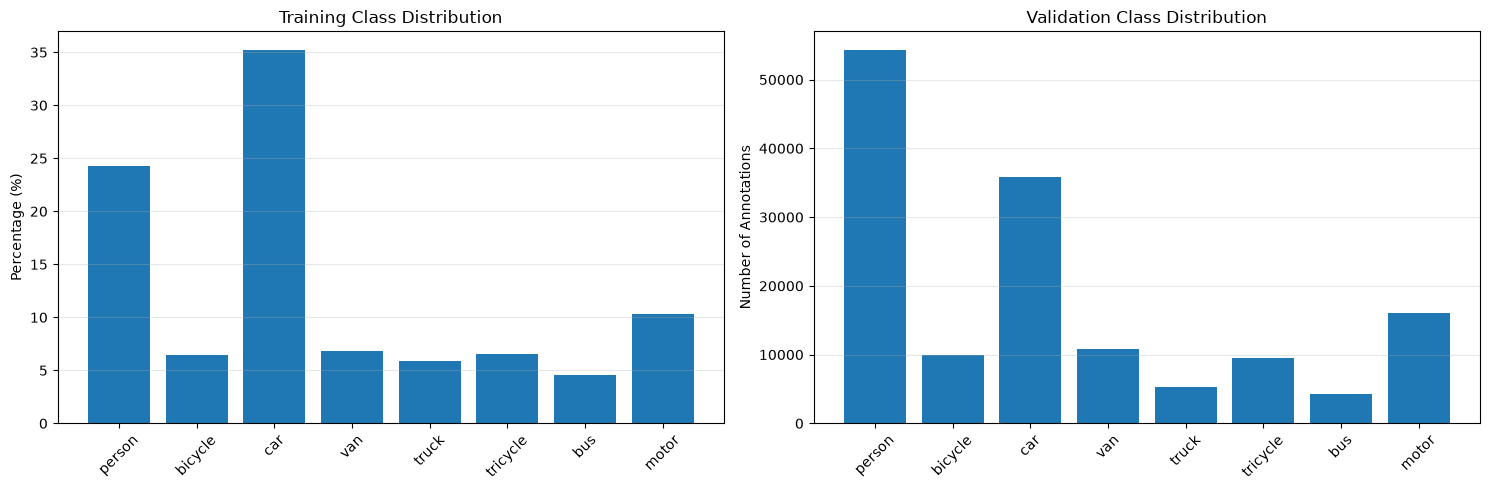

In [31]:

from collections import Counter

# Category names and annotation counts
categories = {
    category["id"]: category["name"]
    for category in train_coco["categories"]
}

train_counts = Counter(
    ann["category_id"] for ann in train_coco["annotations"]
)

val_counts = Counter(
    ann["category_id"] for ann in val_coco["annotations"]
)

class_distribution = pd.DataFrame({
    "Class": list(categories.values()),
    "Train": [train_counts.get(i, 0) for i in categories],
    "Validation": [val_counts.get(i, 0) for i in categories],
})

class_distribution["Train (%)"] = (
    class_distribution["Train"]
    / class_distribution["Train"].sum() * 100
)

display(class_distribution)

# Compare class distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    class_distribution["Class"],
    class_distribution["Train (%)"],
)
axes[0].set_title("Training Class Distribution")
axes[0].set_ylabel("Percentage (%)")

axes[1].bar(
    class_distribution["Class"],
    class_distribution["Validation"],
)
axes[1].set_title("Validation Class Distribution")
axes[1].set_ylabel("Number of Annotations")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 3.3 Object Size Distribution

We analyze bounding box dimensions and object areas to understand the scale of objects in the dataset.

Objects are grouped into small, medium, and large categories using COCO area thresholds. This analysis helps us select appropriate image resolutions and anchor configurations for object detection models.


Bounding box statistics:


,width,height,area
count,1105516.00,1105516.00,1105516.00
mean,60.97,56.80,4667.81
std,51.85,35.24,8896.62
min,4.00,4.00,60.00
25%,27.00,34.00,1025.00
50%,44.00,48.00,2100.00
75%,77.00,69.00,4615.00
max,698.00,758.00,494216.00



Object size distribution:


,Count,Percentage (%)
size,,
Small,275347,24.91
Medium,702004,63.50
Large,128165,11.59


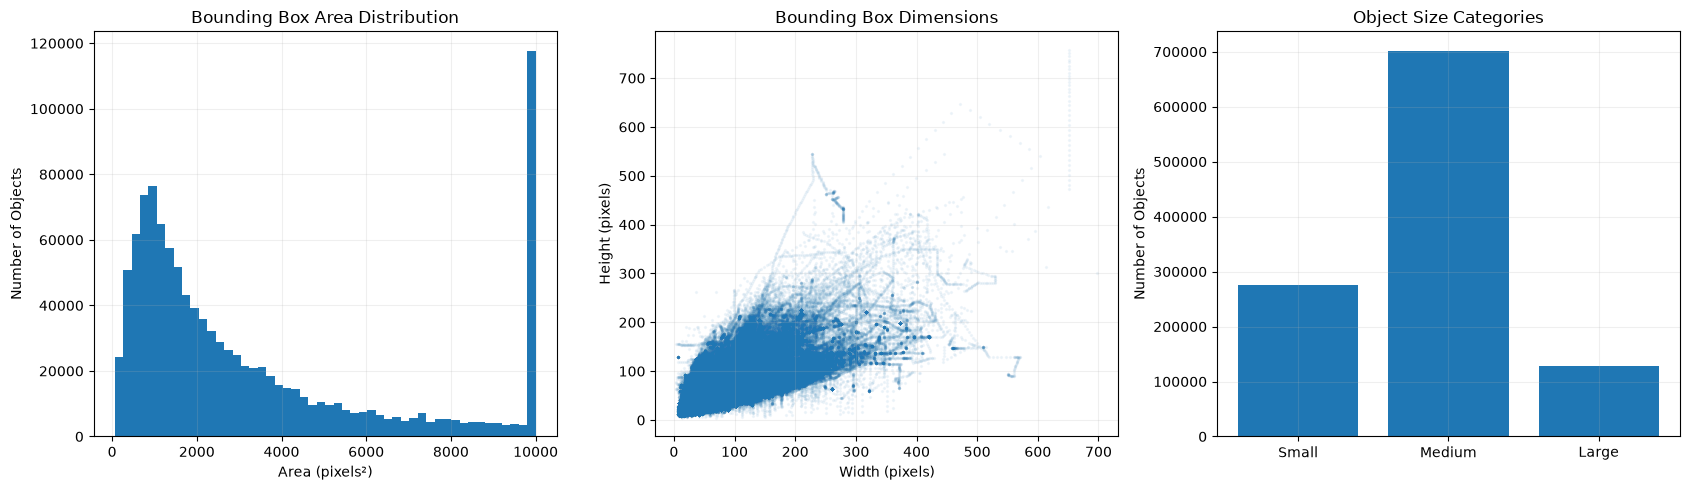

In [32]:

# Extract bounding box dimensions
boxes = pd.DataFrame([
    {
        "width": ann["bbox"][2],
        "height": ann["bbox"][3],
        "area": ann["bbox"][2] * ann["bbox"][3],
    }
    for ann in train_coco["annotations"]
    if ann.get("iscrowd", 0) == 0
    and ann.get("ignore", 0) == 0
    and ann["category_id"] in categories
])

# COCO object size thresholds
boxes["size"] = pd.cut(
    boxes["area"],
    bins=[-1, 32**2, 96**2, float("inf")],
    labels=["Small", "Medium", "Large"],
    right=False,
)

size_distribution = (
    boxes["size"]
    .value_counts()
    .reindex(["Small", "Medium", "Large"])
)

print("Bounding box statistics:")
display(boxes[["width", "height", "area"]].describe().round(2))

print("\nObject size distribution:")
display(pd.DataFrame({
    "Count": size_distribution,
    "Percentage (%)": (
        size_distribution / size_distribution.sum() * 100
    ).round(2),
}))

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(
    boxes["area"].clip(upper=10000),
    bins=50,
)
axes[0].set_title("Bounding Box Area Distribution")
axes[0].set_xlabel("Area (pixels²)")
axes[0].set_ylabel("Number of Objects")

axes[1].scatter(
    boxes["width"],
    boxes["height"],
    s=2,
    alpha=0.05,
)
axes[1].set_title("Bounding Box Dimensions")
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")

axes[2].bar(
    size_distribution.index,
    size_distribution.values,
)
axes[2].set_title("Object Size Categories")
axes[2].set_ylabel("Number of Objects")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### 3.4 Scene Density

We analyze the number of target objects per frame to understand how crowded the scenes are.

This information will help us configure the number of region proposals and detections per image in the object detection models.


Objects per frame:


count    24201.00
mean        45.68
std         31.56
min          0.00
25%         22.00
50%         43.00
75%         57.00
max        180.00
Name: object_count, dtype: float64


Top 10 densest sequences:


,mean,median,max
video_id,,,
15,142.96,150.0,156
14,132.22,130.0,166
13,124.57,129.0,134
6,110.38,108.0,124
19,108.89,102.0,174
34,95.35,108.0,126
52,91.89,93.0,104
8,89.95,85.0,113
54,85.80,86.0,94


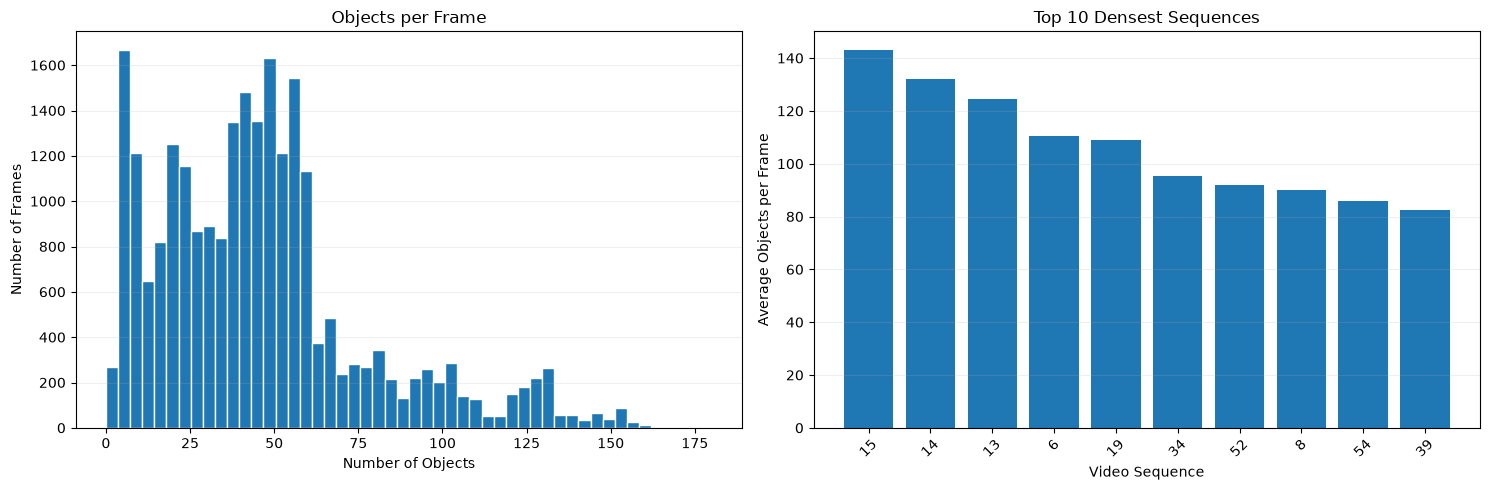

In [33]:

# Count target objects per image
target_annotations = [
    ann for ann in train_coco["annotations"]
    if ann["category_id"] in categories
    and ann.get("iscrowd", 0) == 0
    and ann.get("ignore", 0) == 0
]

objects_per_image = Counter(
    ann["image_id"] for ann in target_annotations
)

# Include frames without target objects
image_counts = pd.DataFrame([
    {
        "image_id": image["id"],
        "video_id": image.get("video_id"),
        "object_count": objects_per_image.get(image["id"], 0),
    }
    for image in train_coco["images"]
])

print("Objects per frame:")
display(image_counts["object_count"].describe().round(2))

# Average density per video sequence
sequence_density = (
    image_counts.groupby("video_id")["object_count"]
    .agg(["mean", "median", "max"])
    .sort_values("mean", ascending=False)
)

print("\nTop 10 densest sequences:")
display(sequence_density.head(10).round(2))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    image_counts["object_count"],
    bins=50,
    edgecolor="white",
)
axes[0].set_title("Objects per Frame")
axes[0].set_xlabel("Number of Objects")
axes[0].set_ylabel("Number of Frames")

axes[1].bar(
    range(10),
    sequence_density["mean"].head(10),
)
axes[1].set_title("Top 10 Densest Sequences")
axes[1].set_xlabel("Video Sequence")
axes[1].set_ylabel("Average Objects per Frame")
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(
    sequence_density.head(10).index,
    rotation=45,
)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()



### 3.5 Ground Truth Visualization

We visualize sample frames with their ground-truth bounding boxes to inspect annotation quality, object scale, and scene density.


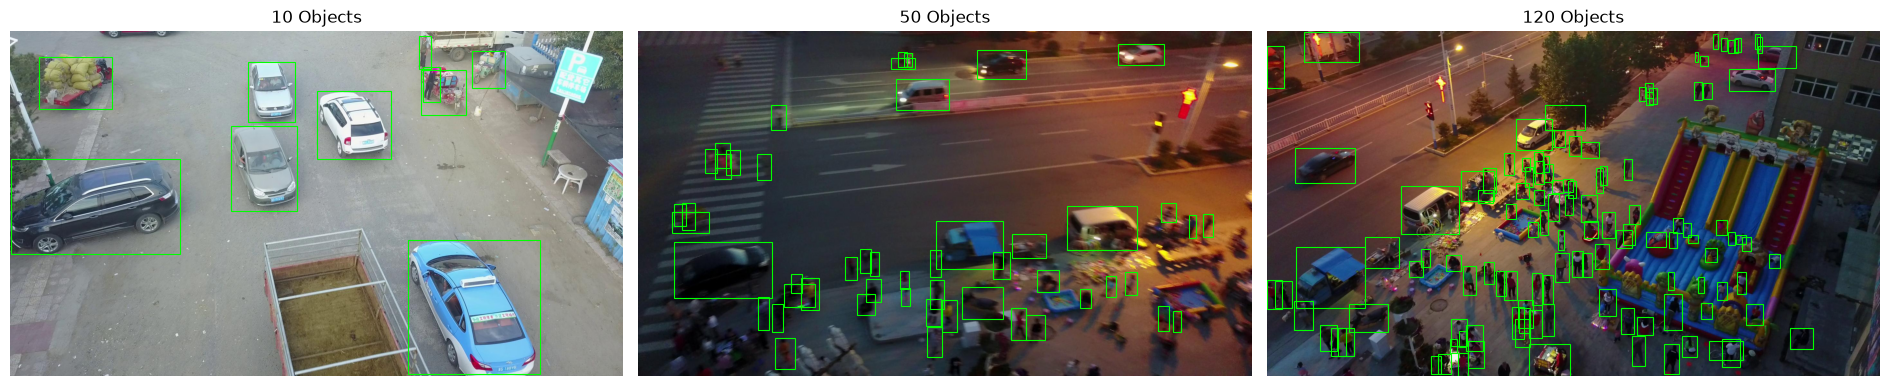

In [34]:

from collections import defaultdict
from matplotlib.patches import Rectangle

# Group annotations by image
annotations_by_image = defaultdict(list)

for ann in target_annotations:
    annotations_by_image[ann["image_id"]].append(ann)

# Select frames with different object densities
sample_counts = [10, 50, 120]

selected_images = []

for target_count in sample_counts:
    closest_image = min(
        train_coco["images"],
        key=lambda img: abs(
            objects_per_image.get(img["id"], 0) - target_count
        ),
    )
    selected_images.append(closest_image)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, image_info in zip(axes, selected_images):
    image_path = TRAIN_PATH / image_info["file_name"]

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)

    for ann in annotations_by_image[image_info["id"]]:
        x, y, width, height = ann["bbox"]

        box = Rectangle(
            (x, y),
            width,
            height,
            linewidth=0.8,
            edgecolor="lime",
            facecolor="none",
        )

        ax.add_patch(box)

    count = objects_per_image.get(image_info["id"], 0)

    ax.set_title(f"{count} Objects")
    ax.axis("off")

plt.tight_layout()
plt.show()



## 4. Data Preprocessing

### 4.1 Annotation Validation and Ignored Regions

We inspect annotation metadata and distinguish valid target objects from ignored annotations. This is necessary to avoid treating ignored regions as ordinary training targets or background during evaluation.


In [35]:

# Inspect annotation fields
print("Annotation example:")
display(train_coco["annotations"][0])

# Count target and ignored annotations
annotation_summary = pd.DataFrame([
    {
        "Split": split_name,
        "Total": len(coco["annotations"]),
        "Target": sum(
            ann["category_id"] in categories
            and ann.get("iscrowd", 0) == 0
            and ann.get("ignore", 0) == 0
            for ann in coco["annotations"]
        ),
        "Crowd": sum(
            ann.get("iscrowd", 0) == 1
            for ann in coco["annotations"]
        ),
        "Ignored": sum(
            ann.get("ignore", 0) == 1
            for ann in coco["annotations"]
        ),
        "Other categories": sum(
            ann["category_id"] not in categories
            for ann in coco["annotations"]
        ),
    }
    for split_name, coco in [
        ("Train", train_coco),
        ("Validation", val_coco),
    ]
])

display(annotation_summary)


Annotation example:


{'id': 1,
 'image_id': 1,
 'category_id': 1,
 'bbox': [424, 543, 35, 88],
 'area': 3080,
 'iscrowd': 0,
 'truncation': 0,
 'occlusion': 0,
 'track_id': 2,
 'orig_category_id': 1}

,Split,Total,Target,Crowd,Ignored,Other categories
0,Train,1616260,1105516,510744,510744,0
1,Validation,146092,114132,31960,31960,0



### 4.2 Train/Validation Split Verification

The dataset provides predefined training and validation splits.

We verify that the splits contain different video sequences to prevent data leakage between highly correlated frames.


In [36]:

# Extract video identifiers
train_videos = {
    video["name"] if "name" in video else video["id"]
    for video in train_coco["videos"]
}

val_videos = {
    video["name"] if "name" in video else video["id"]
    for video in val_coco["videos"]
}

# Check whether any sequences appear in both splits
overlapping_videos = train_videos & val_videos

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation"],
    "Sequences": [len(train_videos), len(val_videos)],
    "Frames": [
        len(train_coco["images"]),
        len(val_coco["images"]),
    ],
})

display(split_summary)

print("Overlapping video sequences:", len(overlapping_videos))

assert not overlapping_videos, "Train/validation sequence leakage detected!"

print("Train/validation sequence separation verified.")


,Split,Sequences,Frames
0,Train,56,24201
1,Validation,7,2846


Overlapping video sequences: 0
Train/validation sequence separation verified.



### 4.3 Image Resizing and Normalization

We resize images while preserving their aspect ratio and apply the same geometric transformation to bounding boxes.

For Faster R-CNN and RetinaNet, image normalization will be handled by the corresponding model preprocessing pipeline.


Original image: (1071, 1904, 3)
Resized image: (504, 896, 3)
Number of boxes: 10


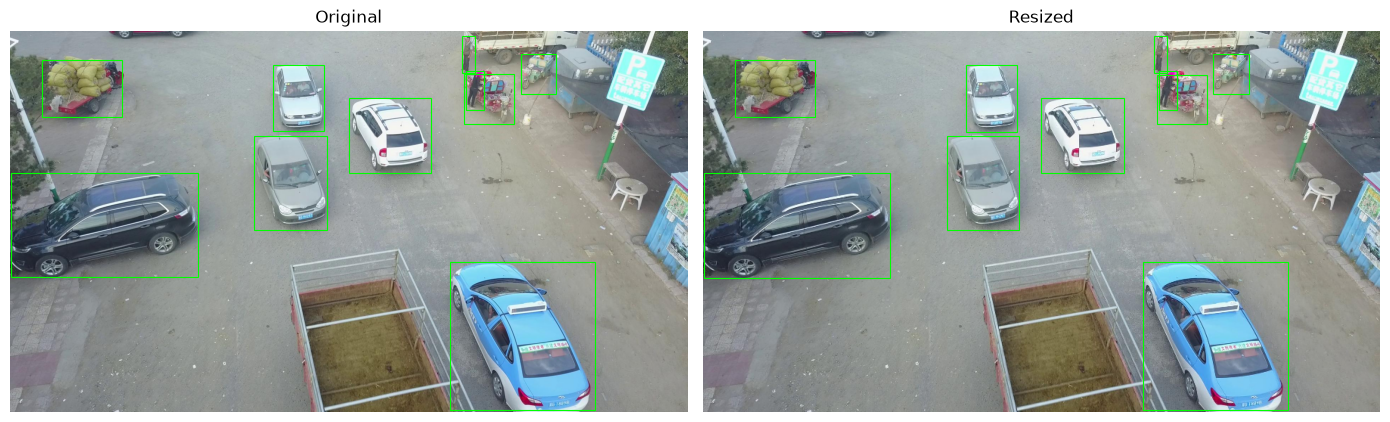

In [37]:

def resize_image_and_boxes(image, boxes, max_size=896):
    height, width = image.shape[:2]

    scale = min(max_size / max(height, width), 1.0)

    new_width = round(width * scale)
    new_height = round(height * scale)

    resized_image = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_LINEAR,
    )

    resized_boxes = boxes.copy().astype(np.float32)
    resized_boxes *= scale

    return resized_image, resized_boxes


# Select a sample frame
sample_info = selected_images[0]
sample_path = TRAIN_PATH / sample_info["file_name"]

original_image = cv2.cvtColor(
    cv2.imread(str(sample_path)),
    cv2.COLOR_BGR2RGB,
)

original_boxes = np.array(
    [
        ann["bbox"]
        for ann in annotations_by_image[sample_info["id"]]
    ],
    dtype=np.float32,
).reshape(-1, 4)

resized_image, resized_boxes = resize_image_and_boxes(
    original_image,
    original_boxes,
)

print("Original image:", original_image.shape)
print("Resized image:", resized_image.shape)
print("Number of boxes:", len(resized_boxes))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, image, boxes, title in zip(
    axes,
    [original_image, resized_image],
    [original_boxes, resized_boxes],
    ["Original", "Resized"],
):
    ax.imshow(image)

    for x, y, width, height in boxes:
        ax.add_patch(
            Rectangle(
                (x, y),
                width,
                height,
                edgecolor="lime",
                facecolor="none",
                linewidth=0.8,
            )
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()



### 4.4 Data Augmentation

We apply simple data augmentations to increase the diversity of training samples.

Horizontal flipping requires updating bounding box coordinates, while brightness and contrast adjustments modify only image pixels.

Augmentations are applied to training data only.


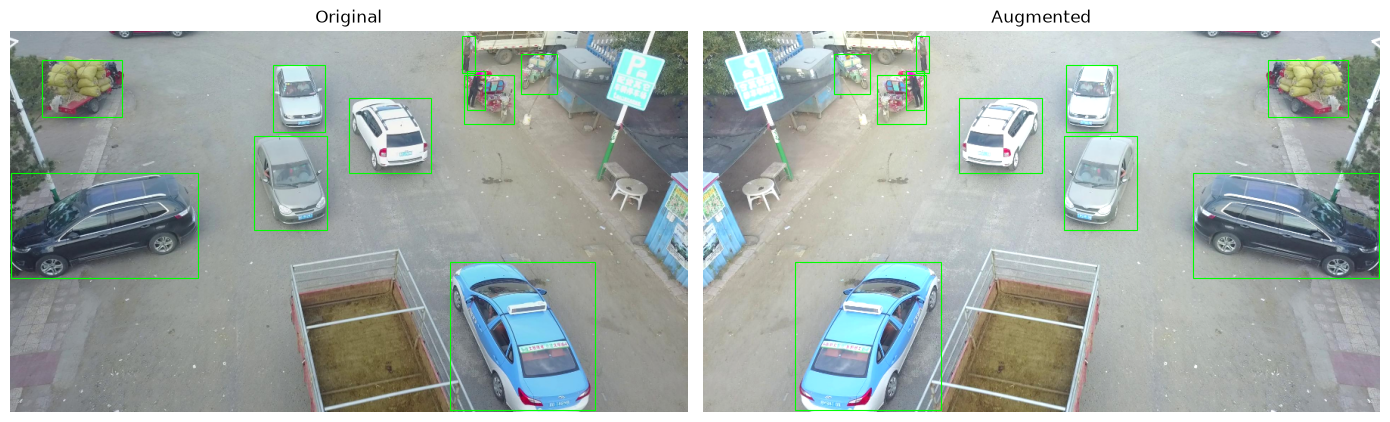

In [38]:

def augment_image(image, boxes, flip=False, alpha=1.0, beta=0):
    augmented_image = image.copy()
    augmented_boxes = boxes.copy().astype(np.float32)

    if flip:
        augmented_image = cv2.flip(augmented_image, 1)

        image_width = image.shape[1]
        augmented_boxes[:, 0] = (
            image_width - boxes[:, 0] - boxes[:, 2]
        )

    augmented_image = cv2.convertScaleAbs(
        augmented_image,
        alpha=alpha,
        beta=beta,
    )

    return augmented_image, augmented_boxes


# Apply augmentation to a sample frame
augmented_image, augmented_boxes = augment_image(
    resized_image,
    resized_boxes,
    flip=True,
    alpha=1.15,
    beta=10,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, image, boxes, title in zip(
    axes,
    [resized_image, augmented_image],
    [resized_boxes, augmented_boxes],
    ["Original", "Augmented"],
):
    ax.imshow(image)

    for x, y, width, height in boxes:
        ax.add_patch(
            Rectangle(
                (x, y),
                width,
                height,
                edgecolor="lime",
                facecolor="none",
                linewidth=0.8,
            )
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()



## 5. Faster R-CNN

### 5.1 Dataset Preparation

We implement a PyTorch Dataset that loads images and converts COCO annotations into the format expected by torchvision detection models.

Training targets contain valid object bounding boxes and class labels. Ignored regions are excluded from training targets and must be handled separately during evaluation.


In [39]:

import torch
from torch.utils.data import Dataset
from torchvision.transforms.functional import to_tensor


class VisDroneDataset(Dataset):
    def __init__(self, images_path, coco, augment=False):
        self.images_path = Path(images_path)
        self.images = coco["images"]
        self.augment = augment

        self.annotations = defaultdict(list)

        for ann in coco["annotations"]:
            if ann.get("iscrowd", 0) == 1:
                continue

            if ann["category_id"] not in categories:
                continue

            self.annotations[ann["image_id"]].append(ann)

        self.category_ids = {
            category_id: index + 1
            for index, category_id in enumerate(sorted(categories))
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_path = self.images_path / image_info["file_name"]

        image = cv2.imread(str(image_path))

        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        height, width = image.shape[:2]
        boxes = []
        labels = []

        for ann in self.annotations[image_info["id"]]:
            x, y, w, h = ann["bbox"]

            x1 = max(0, x)
            y1 = max(0, y)
            x2 = min(width, x + w)
            y2 = min(height, y + h)

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append([x1, y1, x2, y2])
            labels.append(self.category_ids[ann["category_id"]])

        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        if self.augment and random.random() < 0.5:
            image = cv2.flip(image, 1).copy()

            if len(boxes):
                left = boxes[:, 0].clone()
                right = boxes[:, 2].clone()

                boxes[:, 0] = width - right
                boxes[:, 2] = width - left

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(image_info["id"]),
            "area": (
                (boxes[:, 2] - boxes[:, 0])
                * (boxes[:, 3] - boxes[:, 1])
            ),
            "iscrowd": torch.zeros(len(boxes), dtype=torch.int64),
        }

        return to_tensor(image), target


In [40]:

from torch.utils.data import DataLoader

train_dataset = VisDroneDataset(
    TRAIN_PATH,
    train_coco,
    augment=True,
)

val_dataset = VisDroneDataset(
    VAL_PATH,
    val_coco,
    augment=False,
)

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn,
)

image, target = train_dataset[0]

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Image shape:", image.shape)
print("Bounding boxes:", target["boxes"].shape)
print("Labels:", torch.unique(target["labels"]).tolist())

assert image.shape[0] == 3
assert target["boxes"].shape[1] == 4
assert len(target["boxes"]) == len(target["labels"])
assert torch.all(target["boxes"][:, 2] > target["boxes"][:, 0])
assert torch.all(target["boxes"][:, 3] > target["boxes"][:, 1])

print("Dataset verification passed.")


Training images: 24201
Validation images: 2846
Image shape: torch.Size([3, 756, 1344])
Bounding boxes: torch.Size([23, 4])
Labels: [1, 6, 8]
Dataset verification passed.


In [41]:

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn_v2(
    weights=weights,
    min_size=512,
    max_size=896,
)

# Replace the classification head
num_classes = len(categories) + 1

in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes,
)

model = model.to(device)

print("Device:", device)
print("Number of classes:", num_classes)
print("Model initialized successfully.")


Device: cuda
Number of classes: 9
Model initialized successfully.



### 5.4 Training Smoke Test

Before training, we run one forward and backward pass to verify that the model accepts our dataset format and computes valid training losses.

Faster R-CNN uses four loss components: classification loss, box regression loss, RPN objectness loss, and RPN box regression loss.


In [42]:

# Load one training batch
images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]

targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

# Forward pass
model.train()
model.zero_grad(set_to_none=True)

loss_dict = model(images, targets)

total_loss = sum(loss_dict.values())

print("Training losses:")

for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print(f"\nTotal loss: {total_loss.item():.4f}")

# Backward pass
assert torch.isfinite(total_loss), "Non-finite training loss!"

total_loss.backward()

print("\nForward and backward passes completed successfully.")

model.zero_grad(set_to_none=True)


Training losses:
loss_classifier: 2.0701
loss_box_reg: 0.7514
loss_objectness: 2.0274
loss_rpn_box_reg: 0.4445

Total loss: 5.2933

Forward and backward passes completed successfully.


In [43]:

from torch.utils.data import Subset
from collections import defaultdict
from tqdm.auto import tqdm

# Training configuration
EPOCHS = 3
LEARNING_RATE = 1e-4
FRAMES_PER_SEQUENCE = 10

# Group image indices by video
sequence_indices = defaultdict(list)

for index, image_info in enumerate(train_dataset.images):
    sequence_indices[image_info["video_id"]].append(index)

# Select evenly spaced frames from each sequence
selected_indices = []

for indices in sequence_indices.values():
    positions = np.linspace(
        0,
        len(indices) - 1,
        min(FRAMES_PER_SEQUENCE, len(indices)),
        dtype=int,
    )
    selected_indices.extend(indices[pos] for pos in positions)

train_subset = Subset(train_dataset, selected_indices)

baseline_loader = DataLoader(
    train_subset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn,
)

print("Training frames:", len(train_subset))
print("Epochs:", EPOCHS)
print("Total training steps:", len(baseline_loader) * EPOCHS)


Training frames: 560
Epochs: 3
Total training steps: 1680


In [44]:

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=device.type == "cuda",
)

training_history = []

for epoch in range(EPOCHS):
    model.train()

    epoch_loss = 0.0

    progress = tqdm(
        baseline_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}",
    )

    for images, targets in progress:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda",
        ):
            losses = model(images, targets)
            total_loss = sum(losses.values())

        if not torch.isfinite(total_loss):
            raise RuntimeError("Non-finite training loss detected")

        scaler.scale(total_loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0,
        )

        scaler.step(optimizer)
        scaler.update()

        epoch_loss += total_loss.item()

        progress.set_postfix(
            loss=f"{total_loss.item():.4f}"
        )

    average_loss = epoch_loss / len(baseline_loader)
    training_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} — "
        f"Average loss: {average_loss:.4f}"
    )

# Save trained weights
CHECKPOINT_DIR = PROJECT_ROOT / "outputs" / "manual_fasterrcnn"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    model.state_dict(),
    CHECKPOINT_DIR / "baseline.pt",
)

print("Baseline checkpoint saved.")


Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 1/3 — Average loss: 1.1975


Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 0.9291


Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 0.8359
Baseline checkpoint saved.



### 5.6 Faster R-CNN Evaluation

We evaluate the trained Faster R-CNN baseline on the validation set using standard COCO detection metrics.

The evaluation includes mAP, AP50, AP75, and average precision across different object sizes. Original category IDs and crowd annotations are preserved to ensure correct evaluation.


In [45]:

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Original COCO category IDs corresponding to model labels
label_to_category = {
    label: category_id
    for category_id, label in train_dataset.category_ids.items()
}

def evaluate_model(model, data_loader, annotation_path, device):
    model.eval()

    predictions = []

    with torch.inference_mode():
        for images, targets in tqdm(
            data_loader,
            desc="Evaluating",
        ):
            images = [image.to(device) for image in images]
            outputs = model(images)

            for output, target in zip(outputs, targets):
                image_id = int(target["image_id"].item())

                boxes = output["boxes"].cpu().numpy()
                scores = output["scores"].cpu().numpy()
                labels = output["labels"].cpu().numpy()

                for box, score, label in zip(boxes, scores, labels):
                    if score < 0.001:
                        continue

                    if int(label) not in label_to_category:
                        continue

                    x1, y1, x2, y2 = box

                    predictions.append({
                        "image_id": image_id,
                        "category_id": label_to_category[int(label)],
                        "bbox": [
                            float(x1),
                            float(y1),
                            float(x2 - x1),
                            float(y2 - y1),
                        ],
                        "score": float(score),
                    })

    if not predictions:
        raise ValueError("No predictions were generated.")

    # Load original validation annotations, including crowd regions
    coco_gt = COCO(str(annotation_path))
    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")

    # Evaluate only images included in this DataLoader
    evaluator.params.imgIds = [
        int(data_loader.dataset[i][1]["image_id"].item())
        for i in range(len(data_loader.dataset))
    ]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    metric_names = [
        "mAP",
        "AP50",
        "AP75",
        "AP_small",
        "AP_medium",
        "AP_large",
    ]

    return dict(zip(metric_names, evaluator.stats[:6]))


baseline_metrics = evaluate_model(
    model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

display(
    pd.DataFrame(
        [baseline_metrics],
        index=["Faster R-CNN Baseline"],
    ).round(4)
)


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4ea3ffff60>
Traceback (most recent call last):
  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^Exception ignored in: ^^<function _MultiProcessingDataLoaderIter.__del__ at 0x7d4ea3ffff60>^
^Traceback (most recent call last):
^  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1706, in __del__
^    ^self._shutdown_workers()^
^  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers


loading annotations into memory...
Done (t=0.45s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.36s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=59.39s).
Accumulating evaluation results...
DONE (t=2.31s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.127
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.260
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.113
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.052
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.111
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.259
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.067
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.165
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
Faster R-CNN Baseline,0.1273,0.2596,0.1131,0.0522,0.1105,0.2589



### 5.7 RPN Proposal Tuning

We investigate whether changing the number of RPN proposals improves object detection in dense scenes.

The tuned model uses the same training subset, optimizer, image resolution, and number of epochs as the baseline.


In [46]:

# Keep the trained baseline unchanged
model = model.cpu()
torch.cuda.empty_cache()

# Initialize an independent model
torch.manual_seed(SEED)

rpn_model = fasterrcnn_resnet50_fpn_v2(
    weights=weights,
    min_size=512,
    max_size=896,
    rpn_pre_nms_top_n_train=3000,
    rpn_post_nms_top_n_train=1000,
    rpn_pre_nms_top_n_test=2000,
    rpn_post_nms_top_n_test=1000,
)

in_features = rpn_model.roi_heads.box_predictor.cls_score.in_features

rpn_model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes,
)

rpn_model = rpn_model.to(device)

print("Training pre-NMS:", rpn_model.rpn.pre_nms_top_n())
print("Training post-NMS:", rpn_model.rpn.post_nms_top_n())
print("RPN tuned model initialized.")


Training pre-NMS: 3000
Training post-NMS: 1000
RPN tuned model initialized.


In [47]:

rpn_optimizer = torch.optim.AdamW(
    rpn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)

rpn_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=device.type == "cuda",
)

rpn_history = []

torch.manual_seed(SEED)

for epoch in range(EPOCHS):
    rpn_model.train()
    epoch_loss = 0.0

    progress = tqdm(
        baseline_loader,
        desc=f"RPN Epoch {epoch + 1}/{EPOCHS}",
    )

    for images, targets in progress:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        rpn_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda",
        ):
            loss_dict = rpn_model(images, targets)
            loss = sum(loss_dict.values())

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss detected")

        rpn_scaler.scale(loss).backward()
        rpn_scaler.unscale_(rpn_optimizer)

        torch.nn.utils.clip_grad_norm_(
            rpn_model.parameters(),
            max_norm=5.0,
        )

        rpn_scaler.step(rpn_optimizer)
        rpn_scaler.update()

        epoch_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    average_loss = epoch_loss / len(baseline_loader)
    rpn_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} — "
        f"Average loss: {average_loss:.4f}"
    )

torch.save(
    rpn_model.state_dict(),
    CHECKPOINT_DIR / "rpn_tuned.pt",
)

print("RPN tuned checkpoint saved.")


RPN Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 1/3 — Average loss: 1.3190


RPN Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 1.0530


RPN Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 0.9592
RPN tuned checkpoint saved.


In [48]:

rpn_metrics = evaluate_model(
    rpn_model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

comparison = pd.DataFrame(
    {
        "Faster R-CNN Baseline": baseline_metrics,
        "Faster R-CNN RPN Tuned": rpn_metrics,
    }
).T

comparison["mAP improvement"] = (
    comparison["mAP"] - baseline_metrics["mAP"]
)

display(comparison.round(4))


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.50s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.35s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=82.51s).
Accumulating evaluation results...
DONE (t=1.90s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.129
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.267
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.106
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.076
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.120
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.243
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.072
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.194
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,mAP improvement
Faster R-CNN Baseline,0.1273,0.2596,0.1131,0.0522,0.1105,0.2589,0.0000
Faster R-CNN RPN Tuned,0.1287,0.2668,0.1057,0.0760,0.1200,0.2430,0.0013


In [49]:

# Initialize a new Faster R-CNN model
torch.manual_seed(SEED)

roi_model = fasterrcnn_resnet50_fpn_v2(
    weights=weights,
    min_size=512,
    max_size=896,
    box_batch_size_per_image=256,
    box_positive_fraction=0.50,
)

in_features = roi_model.roi_heads.box_predictor.cls_score.in_features

roi_model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes,
)

# Release the previous model from GPU memory
rpn_model = rpn_model.cpu()
torch.cuda.empty_cache()

roi_model = roi_model.to(device)

print("RoI batch size:", roi_model.roi_heads.fg_bg_sampler.batch_size_per_image)
print("Positive fraction:", roi_model.roi_heads.fg_bg_sampler.positive_fraction)


RoI batch size: 256
Positive fraction: 0.5


In [50]:

def train_detector(model, loader, epochs, learning_rate):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=device.type == "cuda",
    )

    history = []

    for epoch in range(epochs):
        model.train()
        total_epoch_loss = 0.0

        progress = tqdm(
            loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
        )

        for images, targets in progress:
            images = [image.to(device) for image in images]
            targets = [
                {key: value.to(device) for key, value in target.items()}
                for target in targets
            ]

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                enabled=device.type == "cuda",
            ):
                losses = model(images, targets)
                loss = sum(losses.values())

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss detected")

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0,
            )

            scaler.step(optimizer)
            scaler.update()

            total_epoch_loss += loss.item()
            progress.set_postfix(loss=f"{loss.item():.4f}")

        average_loss = total_epoch_loss / len(loader)
        history.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} — "
            f"Average loss: {average_loss:.4f}"
        )

    return history


roi_history = train_detector(
    roi_model,
    baseline_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
)

torch.save(
    roi_model.state_dict(),
    CHECKPOINT_DIR / "roi_tuned.pt",
)

print("RoI tuned checkpoint saved.")


Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 1/3 — Average loss: 1.8469


Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 1.4592


Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 1.3041
RoI tuned checkpoint saved.


In [51]:

roi_metrics = evaluate_model(
    roi_model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

comparison = pd.DataFrame(
    {
        "Baseline": baseline_metrics,
        "RPN Tuned": rpn_metrics,
        "RoI Tuned": roi_metrics,
    }
).T

display(comparison.round(4))


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.51s)
creating index...
index created!
Loading and preparing results...
DONE (t=23.72s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=52.11s).
Accumulating evaluation results...
DONE (t=2.45s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.106
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.227
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.089
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.057
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.100
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.209
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.070
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.167
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
Baseline,0.1273,0.2596,0.1131,0.0522,0.1105,0.2589
RPN Tuned,0.1287,0.2668,0.1057,0.0760,0.1200,0.2430
RoI Tuned,0.1064,0.2275,0.0887,0.0567,0.1004,0.2087



### 5.9 Bounding Box Loss Modification

We investigate the effect of changing the Smooth L1 loss parameter in the Region Proposal Network.

The baseline uses beta = 1/9, while the modified experiment uses beta = 1/3. All other model and training settings are kept unchanged.


In [52]:

import torch.nn.functional as F
from types import MethodType


def modified_rpn_loss(
    self,
    objectness,
    pred_bbox_deltas,
    labels,
    regression_targets,
):
    positive, negative = self.fg_bg_sampler(labels)

    positive = torch.where(torch.cat(positive))[0]
    negative = torch.where(torch.cat(negative))[0]
    sampled = torch.cat([positive, negative])

    objectness = objectness.flatten()
    labels = torch.cat(labels)
    regression_targets = torch.cat(regression_targets)

    box_loss = F.smooth_l1_loss(
        pred_bbox_deltas[positive],
        regression_targets[positive],
        beta=1 / 3,
        reduction="sum",
    ) / sampled.numel()

    objectness_loss = F.binary_cross_entropy_with_logits(
        objectness[sampled],
        labels[sampled],
    )

    return objectness_loss, box_loss


# Initialize independent Faster R-CNN
torch.manual_seed(SEED)

loss_model = fasterrcnn_resnet50_fpn_v2(
    weights=weights,
    min_size=512,
    max_size=896,
)

in_features = loss_model.roi_heads.box_predictor.cls_score.in_features

loss_model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes,
)

# Replace only the RPN loss computation
loss_model.rpn.compute_loss = MethodType(
    modified_rpn_loss,
    loss_model.rpn,
)

# Release previous models from GPU
roi_model = roi_model.cpu()
torch.cuda.empty_cache()

loss_model = loss_model.to(device)

print("Modified RPN Smooth L1 beta: 1/3")
print("Model initialized successfully.")


Modified RPN Smooth L1 beta: 1/3
Model initialized successfully.


In [53]:

# Verify that the modified loss works
images, targets = next(iter(baseline_loader))

images = [image.to(device) for image in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

loss_model.train()

test_losses = loss_model(images, targets)
test_loss = sum(test_losses.values())

assert torch.isfinite(test_loss)

print("Modified RPN box loss:", test_losses["loss_rpn_box_reg"].item())

# Train modified model
torch.manual_seed(SEED)

loss_history = train_detector(
    loss_model,
    baseline_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
)

torch.save(
    loss_model.state_dict(),
    CHECKPOINT_DIR / "loss_tuned.pt",
)

# Evaluate
loss_metrics = evaluate_model(
    loss_model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

comparison = pd.DataFrame({
    "Baseline": baseline_metrics,
    "RPN Tuned": rpn_metrics,
    "RoI Tuned": roi_metrics,
    "Loss Tuned": loss_metrics,
}).T

display(comparison.round(4))


Modified RPN box loss: 0.27676939964294434


Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

[W1105 16:30:38.725447037 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 146800640 bytes (free: 60882944, total: 6086262784).


Epoch 1/3 — Average loss: 1.1237


Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 0.8709


Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 0.7904


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.53s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.36s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=52.99s).
Accumulating evaluation results...
DONE (t=2.18s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.117
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.245
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.098
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.063
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.110
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.224
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.063
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.183
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
Baseline,0.1273,0.2596,0.1131,0.0522,0.1105,0.2589
RPN Tuned,0.1287,0.2668,0.1057,0.0760,0.1200,0.2430
RoI Tuned,0.1064,0.2275,0.0887,0.0567,0.1004,0.2087
Loss Tuned,0.1173,0.2450,0.0980,0.0633,0.1103,0.2244



### 5.10 Faster R-CNN — Final Comparison

We compare four Faster R-CNN configurations: the baseline, RPN proposal tuning, RoI sampling tuning, and modified regression loss.

All experiments use the same training subset, number of epochs, and validation dataset. We compare detection accuracy using COCO metrics and identify the best configuration.


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,mAP Difference
Baseline,0.1273,0.2596,0.1131,0.0522,0.1105,0.2589,0.0000
RPN Tuned,0.1287,0.2668,0.1057,0.0760,0.1200,0.2430,0.0013
RoI Tuned,0.1064,0.2275,0.0887,0.0567,0.1004,0.2087,-0.0209
Loss Tuned,0.1173,0.2450,0.0980,0.0633,0.1103,0.2244,-0.0100


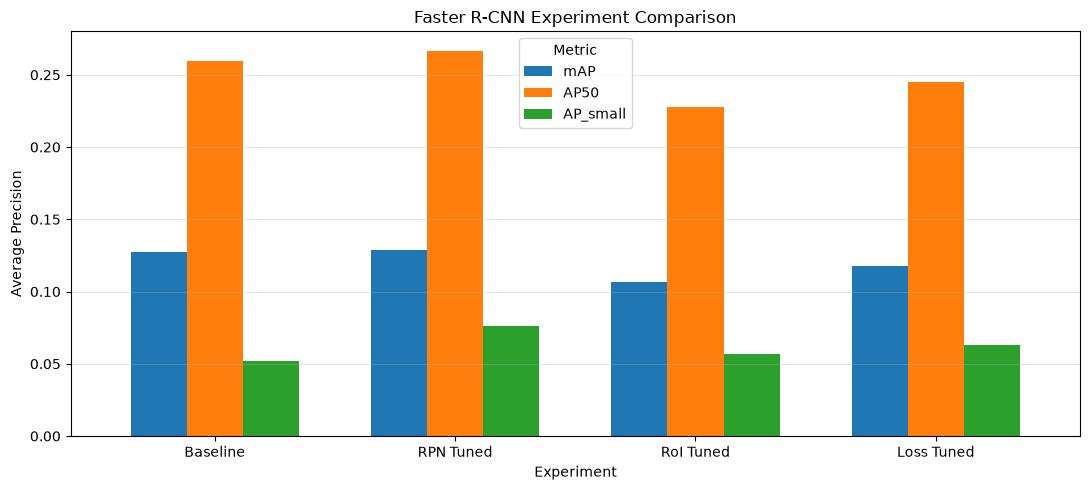

Best Faster R-CNN configuration: RPN Tuned
Best validation mAP: 0.1287
Baseline validation mAP: 0.1273
Absolute mAP improvement: +0.0013


In [54]:

# Compare all Faster R-CNN experiments
results = pd.DataFrame({
    "Baseline": baseline_metrics,
    "RPN Tuned": rpn_metrics,
    "RoI Tuned": roi_metrics,
    "Loss Tuned": loss_metrics,
}).T

# Calculate improvements relative to the baseline
results["mAP Difference"] = (
    results["mAP"] - baseline_metrics["mAP"]
)

display(results.round(4))

# Visualize the main evaluation metrics
metrics = ["mAP", "AP50", "AP_small"]

ax = results[metrics].plot(
    kind="bar",
    figsize=(11, 5),
    width=0.7,
    rot=0,
)

ax.set_title("Faster R-CNN Experiment Comparison")
ax.set_xlabel("Experiment")
ax.set_ylabel("Average Precision")
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Select the best configuration
best_experiment = results["mAP"].idxmax()
best_map = results.loc[best_experiment, "mAP"]
baseline_map = baseline_metrics["mAP"]

print("Best Faster R-CNN configuration:", best_experiment)
print(f"Best validation mAP: {best_map:.4f}")
print(f"Baseline validation mAP: {baseline_map:.4f}")
print(f"Absolute mAP improvement: {best_map - baseline_map:+.4f}")



## 6. RetinaNet — One-stage Anchor-based Detection

RetinaNet is a one-stage object detector that predicts object classes and bounding boxes directly from multi-scale feature maps.

Unlike Faster R-CNN, it does not use a separate region proposal stage. RetinaNet uses Focal Loss to reduce the influence of easy background examples during training.

We compare both detector families using the same training subset and validation protocol.


In [55]:

from torchvision.models.detection import (
    retinanet_resnet50_fpn_v2,
    RetinaNet_ResNet50_FPN_V2_Weights,
)
from torch import nn
import gc

# Initialize pretrained RetinaNet
torch.manual_seed(SEED)

retina_weights = RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT

retina_model = retinanet_resnet50_fpn_v2(
    weights=retina_weights,
    min_size=512,
    max_size=896,
)

# Configure classification head for our dataset
classification_head = retina_model.head.classification_head

num_anchors = retina_model.anchor_generator.num_anchors_per_location()[0]
num_classes = len(categories) + 1

in_channels = classification_head.cls_logits.in_channels

classification_head.cls_logits = nn.Conv2d(
    in_channels,
    num_anchors * num_classes,
    kernel_size=3,
    stride=1,
    padding=1,
)

classification_head.num_classes = num_classes

# Initialize classification layer
nn.init.normal_(
    classification_head.cls_logits.weight,
    std=0.01,
)

prior_probability = 0.01

nn.init.constant_(
    classification_head.cls_logits.bias,
    -np.log((1 - prior_probability) / prior_probability),
)

# Prepare GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()

retina_model = retina_model.to(device)

print("Device:", device)
print("Number of classes:", num_classes)
print("Anchors per location:", num_anchors)
print("RetinaNet initialized successfully.")


Device: cuda
Number of classes: 9
Anchors per location: 9
RetinaNet initialized successfully.


In [56]:

images, targets = next(iter(baseline_loader))

images = [image.to(device) for image in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

retina_model.train()
retina_model.zero_grad(set_to_none=True)

loss_dict = retina_model(images, targets)
total_loss = sum(loss_dict.values())

for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print(f"Total loss: {total_loss.item():.4f}")

assert torch.isfinite(total_loss)

total_loss.backward()
retina_model.zero_grad(set_to_none=True)

print("RetinaNet forward and backward passes passed.")


classification: 1.1342
bbox_regression: 0.2641
Total loss: 1.3983
RetinaNet forward and backward passes passed.



### 6.4 RetinaNet Baseline Training

We fine-tune a pretrained RetinaNet model using the same training subset, image resolution, optimizer, and number of epochs as Faster R-CNN.

The baseline provides a reference for evaluating anchor configuration and Focal Loss modifications.


In [57]:

# Train RetinaNet baseline
retina_history = train_detector(
    retina_model,
    baseline_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
)

# Save trained model
RETINA_DIR = PROJECT_ROOT / "outputs" / "manual_retinanet"
RETINA_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    retina_model.state_dict(),
    RETINA_DIR / "baseline.pt",
)

# Evaluate using the existing COCO evaluator
retina_baseline_metrics = evaluate_model(
    retina_model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

display(
    pd.DataFrame(
        [retina_baseline_metrics],
        index=["RetinaNet Baseline"],
    ).round(4)
)


Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 1/3 — Average loss: 0.6931


Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 0.5182


Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 0.4573


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4ea3ffff60>
Traceback (most recent call last):
  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4ea3ffff60>
Traceback (most recent call last):
  File "/home/marko/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/home/marko/.local/lib/python3.12/site-packages/torch/ut

loading annotations into memory...
Done (t=0.42s)
creating index...
index created!
Loading and preparing results...
DONE (t=23.71s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=69.16s).
Accumulating evaluation results...
DONE (t=5.03s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.108
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.216
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.098
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.042
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.097
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.237
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.067
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.200
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
RetinaNet Baseline,0.1075,0.2157,0.0978,0.0418,0.0971,0.2374



### 6.5 Anchor Configuration Tuning

We investigate smaller anchor sizes to improve detection of small objects in aerial video frames.

The modified model is trained using the same data subset and training budget as the baseline.


In [58]:

from torchvision.models.detection.anchor_utils import AnchorGenerator

def create_retinanet(smaller_anchors=False):
    torch.manual_seed(SEED)

    detector = retinanet_resnet50_fpn_v2(
        weights=retina_weights,
        min_size=512,
        max_size=896,
    )

    if smaller_anchors:
        base_sizes = [16, 32, 64, 128, 256]

        anchor_sizes = tuple(
            tuple(int(size * 2 ** (step / 3)) for step in range(3))
            for size in base_sizes
        )

        aspect_ratios = ((0.5, 1.0, 2.0),) * 5

        detector.anchor_generator = AnchorGenerator(
            sizes=anchor_sizes,
            aspect_ratios=aspect_ratios,
        )

    head = detector.head.classification_head
    num_anchors = detector.anchor_generator.num_anchors_per_location()[0]

    head.cls_logits = nn.Conv2d(
        head.cls_logits.in_channels,
        num_anchors * num_classes,
        kernel_size=3,
        padding=1,
    )

    head.num_classes = num_classes
    head.num_anchors = num_anchors

    nn.init.normal_(head.cls_logits.weight, std=0.01)
    nn.init.constant_(
        head.cls_logits.bias,
        -np.log(99),
    )

    return detector


# Move baseline to CPU
retina_model.cpu()
gc.collect()
torch.cuda.empty_cache()

anchor_model = create_retinanet(
    smaller_anchors=True
).to(device)

print("Modified anchors:", anchor_model.anchor_generator.sizes)

anchor_history = train_detector(
    anchor_model,
    baseline_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
)

torch.save(
    anchor_model.state_dict(),
    RETINA_DIR / "anchors_tuned.pt",
)

anchor_metrics = evaluate_model(
    anchor_model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

display(
    pd.DataFrame(
        {
            "Baseline": retina_baseline_metrics,
            "Smaller Anchors": anchor_metrics,
        }
    ).T.round(4)
)


Modified anchors: ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))


Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 1/3 — Average loss: 0.7448


Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 0.5494


Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 0.4815


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.41s)
creating index...
index created!
Loading and preparing results...
DONE (t=13.55s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=91.68s).
Accumulating evaluation results...
DONE (t=4.58s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.103
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.225
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.081
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.046
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.098
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.210
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.057
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.230
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
Baseline,0.1075,0.2157,0.0978,0.0418,0.0971,0.2374
Smaller Anchors,0.1025,0.2247,0.0812,0.0460,0.0978,0.2104



### 6.6 Focal Loss Tuning

We investigate the effect of the Focal Loss gamma parameter.

The baseline uses gamma = 2.0, while the modified experiment uses gamma = 1.5. This changes the relative contribution of easy and difficult classification examples.


In [59]:

from types import MethodType
from torchvision.ops import sigmoid_focal_loss


def focal_loss_gamma_15(
    self,
    targets,
    head_outputs,
    matched_idxs,
):
    cls_logits = head_outputs["cls_logits"]
    losses = []

    for target, logits, matched in zip(
        targets,
        cls_logits,
        matched_idxs,
    ):
        foreground = matched >= 0
        num_foreground = int(foreground.sum().item())

        class_targets = torch.zeros_like(logits)

        class_targets[
            foreground,
            target["labels"][matched[foreground]],
        ] = 1.0

        valid = matched != self.BETWEEN_THRESHOLDS

        loss = sigmoid_focal_loss(
            logits[valid],
            class_targets[valid],
            alpha=0.25,
            gamma=1.5,
            reduction="sum",
        )

        losses.append(loss / max(1, num_foreground))

    return torch.stack(losses).mean()


# Release previous experiment
anchor_model.cpu()
gc.collect()
torch.cuda.empty_cache()

focal_model = create_retinanet().to(device)

# Modify actual classification loss computation
focal_head = focal_model.head.classification_head

focal_head.compute_loss = MethodType(
    focal_loss_gamma_15,
    focal_head,
)

print("Focal Loss gamma: 1.5")

focal_history = train_detector(
    focal_model,
    baseline_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
)

torch.save(
    focal_model.state_dict(),
    RETINA_DIR / "focal_tuned.pt",
)

focal_metrics = evaluate_model(
    focal_model,
    val_loader,
    VAL_ANNOTATIONS,
    device,
)

display(
    pd.DataFrame(
        {
            "Baseline": retina_baseline_metrics,
            "Smaller Anchors": anchor_metrics,
            "Focal Gamma 1.5": focal_metrics,
        }
    ).T.round(4)
)


Focal Loss gamma: 1.5


Epoch 1/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 1/3 — Average loss: 0.7953


Epoch 2/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 2/3 — Average loss: 0.5890


Epoch 3/3:   0%|          | 0/560 [00:00<?, ?it/s]

Epoch 3/3 — Average loss: 0.5180


Evaluating:   0%|          | 0/2846 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.50s)
creating index...
index created!
Loading and preparing results...
DONE (t=34.40s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=57.41s).
Accumulating evaluation results...
DONE (t=2.53s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.116
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.224
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.107
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.040
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.102
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.265
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.075
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.200
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,mAP,AP50,AP75,AP_small,AP_medium,AP_large
Baseline,0.1075,0.2157,0.0978,0.0418,0.0971,0.2374
Smaller Anchors,0.1025,0.2247,0.0812,0.0460,0.0978,0.2104
Focal Gamma 1.5,0.1163,0.2240,0.1069,0.0403,0.1015,0.2650



### 6.7 Model Comparison

We compare RetinaNet baseline, smaller anchors, and modified Focal Loss.

We also compare the best RetinaNet configuration with Faster R-CNN under the same training and validation protocol.


,mAP,AP50,AP75,AP_small,AP_medium,AP_large
Faster R-CNN (RPN Tuned),0.1287,0.2668,0.1057,0.0760,0.1200,0.2430
RetinaNet Baseline,0.1075,0.2157,0.0978,0.0418,0.0971,0.2374
Smaller Anchors,0.1025,0.2247,0.0812,0.0460,0.0978,0.2104
Focal Gamma 1.5,0.1163,0.2240,0.1069,0.0403,0.1015,0.2650


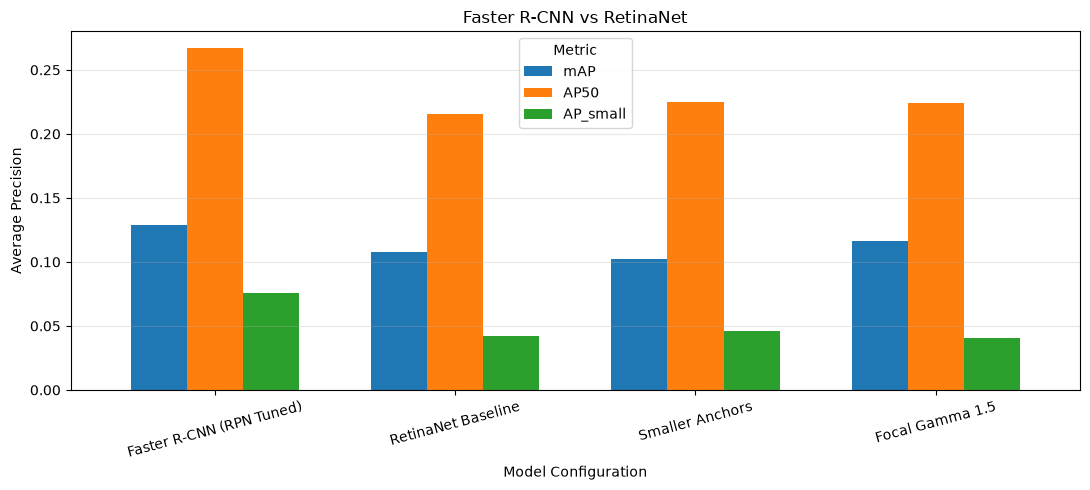

Best RetinaNet: Focal Gamma 1.5
Best RetinaNet mAP: 0.1163
Best Faster R-CNN mAP: 0.1287


In [60]:

# RetinaNet experiment results
retina_results = pd.DataFrame({
    "RetinaNet Baseline": retina_baseline_metrics,
    "Smaller Anchors": anchor_metrics,
    "Focal Gamma 1.5": focal_metrics,
}).T

# Compare against Faster R-CNN
best_faster_name = results["mAP"].idxmax()
best_faster_metrics = results.loc[
    best_faster_name,
    retina_results.columns,
]

final_comparison = pd.concat([
    pd.DataFrame(
        [best_faster_metrics],
        index=[f"Faster R-CNN ({best_faster_name})"],
    ),
    retina_results,
])

display(final_comparison.round(4))

# Visual comparison
ax = final_comparison[
    ["mAP", "AP50", "AP_small"]
].plot(
    kind="bar",
    figsize=(11, 5),
    rot=15,
    width=0.7,
)

ax.set_title("Faster R-CNN vs RetinaNet")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Model Configuration")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Metric")

plt.tight_layout()
plt.show()

best_retina_name = retina_results["mAP"].idxmax()

print("Best RetinaNet:", best_retina_name)
print(
    "Best RetinaNet mAP:",
    f"{retina_results.loc[best_retina_name, 'mAP']:.4f}",
)
print(
    "Best Faster R-CNN mAP:",
    f"{results.loc[best_faster_name, 'mAP']:.4f}",
)


In [61]:

import time

def measure_retina_fps(detector, dataset, samples=30):
    detector.eval()

    indices = np.linspace(
        0,
        len(dataset) - 1,
        samples,
        dtype=int,
    )

    images = [
        dataset[int(i)][0].to(device)
        for i in indices
    ]

    with torch.inference_mode():
        # Warm-up
        for image in images[:5]:
            detector([image])

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for image in images:
            detector([image])

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

    return {
        "Latency (ms)": elapsed / len(images) * 1000,
        "FPS": len(images) / elapsed,
    }


retina_detectors = {
    "RetinaNet Baseline": retina_model,
    "Smaller Anchors": anchor_model,
    "Focal Gamma 1.5": focal_model,
}

speed_results = {}

for name, detector in retina_detectors.items():
    detector.to(device)

    speed_results[name] = measure_retina_fps(
        detector,
        val_dataset,
    )

    detector.cpu()
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

speed_df = pd.DataFrame(speed_results).T

display(speed_df.round(2))


,Latency (ms),FPS
RetinaNet Baseline,57.85,17.29
Smaller Anchors,58.06,17.22
Focal Gamma 1.5,57.88,17.28



### 6.9 Failure Case Analysis

We inspect the predictions of the best RetinaNet configuration on validation images with different object densities.

Ground-truth and predicted bounding boxes are displayed side by side to identify detection errors.


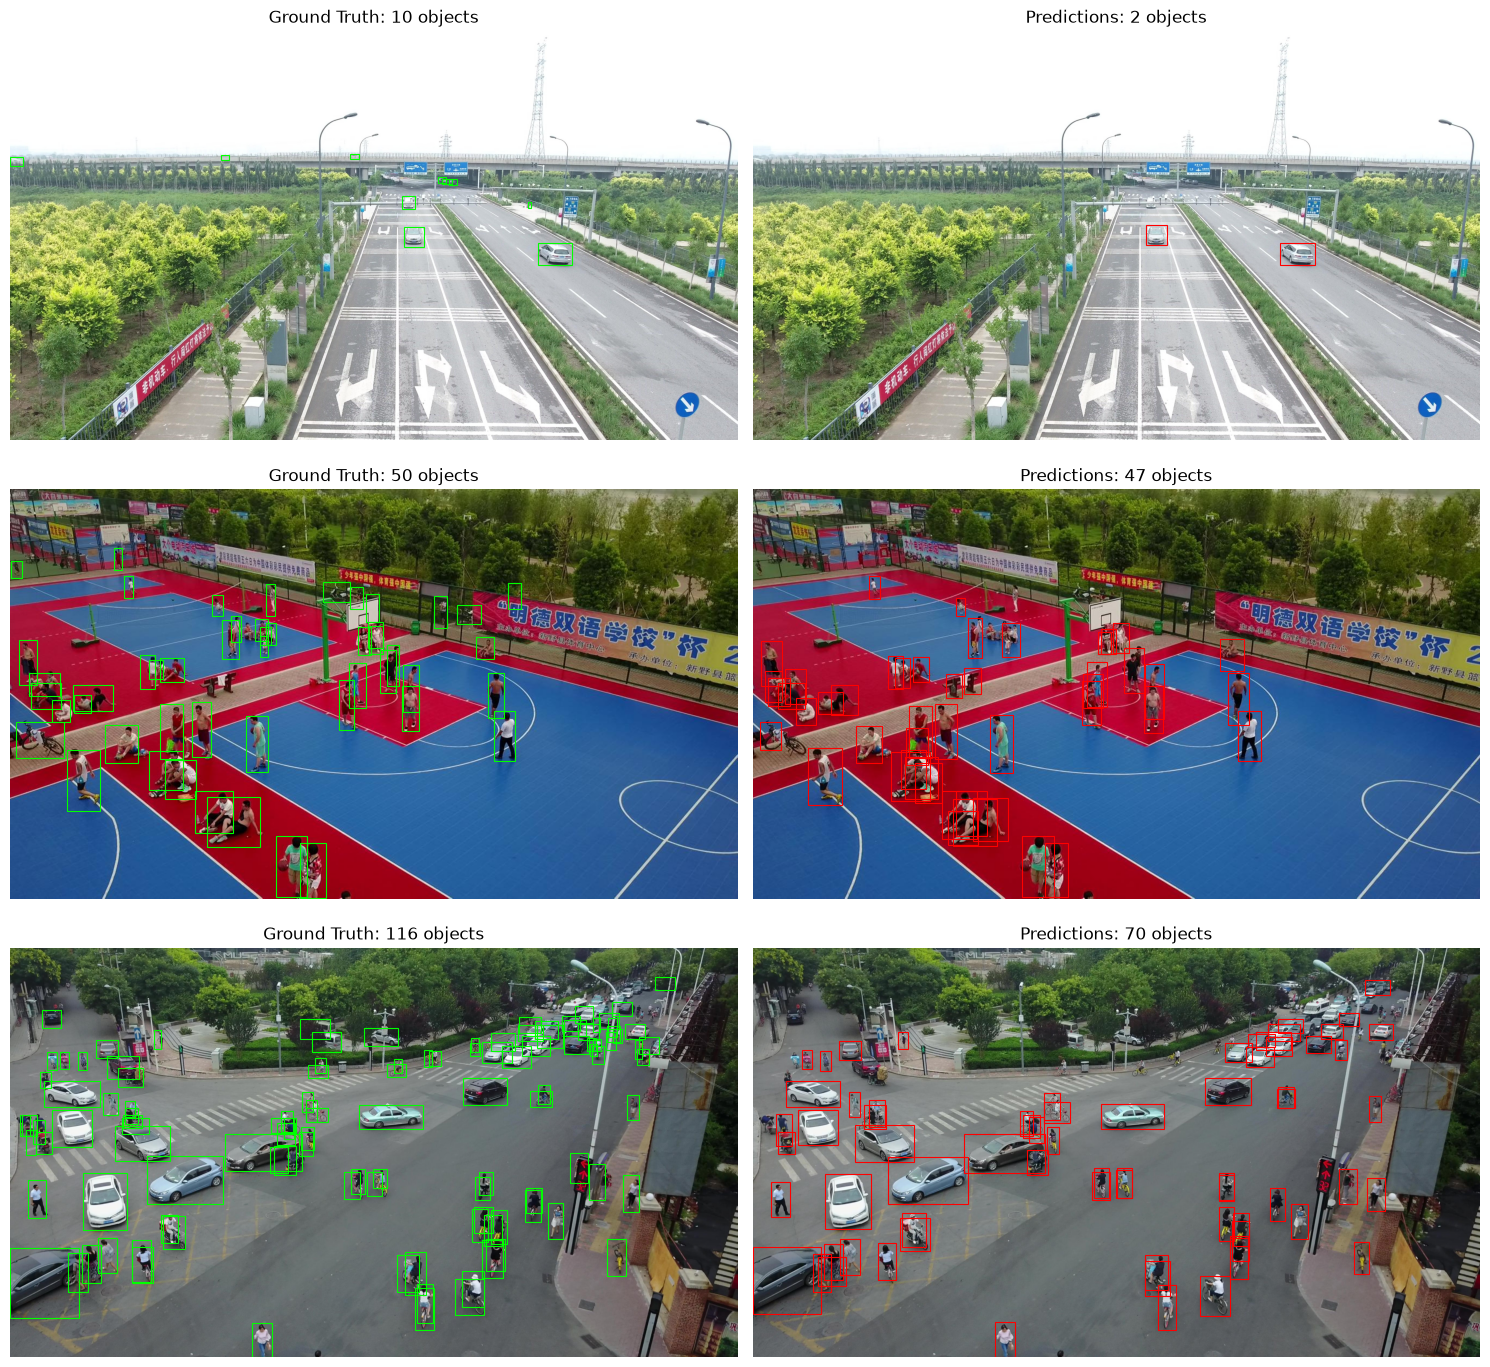

In [62]:

from matplotlib.patches import Rectangle

best_retina = retina_detectors[best_retina_name].to(device)
best_retina.eval()

# Select three frames with different densities
val_counts = defaultdict(int)

for ann in val_coco["annotations"]:
    if ann.get("iscrowd", 0) == 0:
        val_counts[ann["image_id"]] += 1

target_counts = [10, 50, 120]
selected_indices = []

for count in target_counts:
    candidates = [
        i for i in range(len(val_dataset))
        if i not in selected_indices
    ]

    index = min(
        candidates,
        key=lambda i: abs(
            val_counts[val_dataset.images[i]["id"]] - count
        ),
    )

    selected_indices.append(index)


fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for row, index in enumerate(selected_indices):
    image, target = val_dataset[index]

    with torch.inference_mode():
        prediction = best_retina([image.to(device)])[0]

    image_np = image.permute(1, 2, 0).numpy()

    for ax in axes[row]:
        ax.imshow(image_np)
        ax.axis("off")

    # Ground truth
    for x1, y1, x2, y2 in target["boxes"].numpy():
        axes[row, 0].add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                edgecolor="lime",
                facecolor="none",
                linewidth=0.8,
            )
        )

    # Predictions
    detected = 0

    for box, score in zip(
        prediction["boxes"].cpu().numpy(),
        prediction["scores"].cpu().numpy(),
    ):
        if score < 0.3:
            continue

        x1, y1, x2, y2 = box

        axes[row, 1].add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                edgecolor="red",
                facecolor="none",
                linewidth=0.8,
            )
        )

        detected += 1

    axes[row, 0].set_title(
        f"Ground Truth: {len(target['boxes'])} objects"
    )
    axes[row, 1].set_title(
        f"Predictions: {detected} objects"
    )

plt.tight_layout()
plt.show()

best_retina.cpu()

if device.type == "cuda":
    torch.cuda.empty_cache()
